# 04 Decision Tree
Goal: classify order lines as profit or loss and find the discount level where lines typically turn loss-making. Profit and Margin are excluded to avoid target leakage. The tree shows association, not cause.

In [7]:
import os
if os.path.basename(os.getcwd()) == "Notebooks":
    os.chdir("..")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

df = pd.read_csv("Data/Clean/saas_clean.csv")
df.columns = [c.replace(" ", "_") for c in df.columns]
X = pd.get_dummies(df[['Discount','Quantity','Sales','Segment','Product','Region']])
y = df['Is_Loss']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(os.getcwd(), X.shape)

C:\Saas-Sales-Profitability (9994, 23)


In [8]:
for d in [2, 3, 4]:
    t = DecisionTreeClassifier(max_depth=d, min_samples_leaf=100, random_state=42).fit(X_train, y_train)
    print("depth", d, "| train acc:", round(t.score(X_train, y_train),3), "| test acc:", round(t.score(X_test, y_test),3))
base = (X_test['Discount'] > 0.20).astype(int)
print("Baseline rule 'discount > 20% = loss' accuracy:", round((base == y_test).mean(), 3))

depth 2 | train acc: 0.943 | test acc: 0.944
depth 3 | train acc: 0.943 | test acc: 0.944
depth 4 | train acc: 0.947 | test acc: 0.951
Baseline rule 'discount > 20% = loss' accuracy: 0.944


In [9]:
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=100, random_state=42).fit(X_train, y_train)
pred = tree.predict(X_test)
print(classification_report(y_test, pred, target_names=['Profit','Loss']))
print(confusion_matrix(y_test, pred))
print(export_text(tree, feature_names=list(X.columns)))

              precision    recall  f1-score   support

      Profit       0.94      0.99      0.97      2031
        Loss       0.97      0.72      0.83       468

    accuracy                           0.94      2499
   macro avg       0.95      0.86      0.90      2499
weighted avg       0.95      0.94      0.94      2499

[[2020   11]
 [ 129  339]]
|--- Discount <= 0.25
|   |--- Discount <= 0.13
|   |   |--- Product_FinanceHub <= 0.50
|   |   |   |--- class: 0
|   |   |--- Product_FinanceHub >  0.50
|   |   |   |--- class: 0
|   |--- Discount >  0.13
|   |   |--- Product_Marketing Suite - Gold <= 0.50
|   |   |   |--- class: 0
|   |   |--- Product_Marketing Suite - Gold >  0.50
|   |   |   |--- class: 0
|--- Discount >  0.25
|   |--- Discount <= 0.42
|   |   |--- Product_ContactMatcher <= 0.50
|   |   |   |--- class: 1
|   |   |--- Product_ContactMatcher >  0.50
|   |   |   |--- class: 1
|   |--- Discount >  0.42
|   |   |--- class: 1



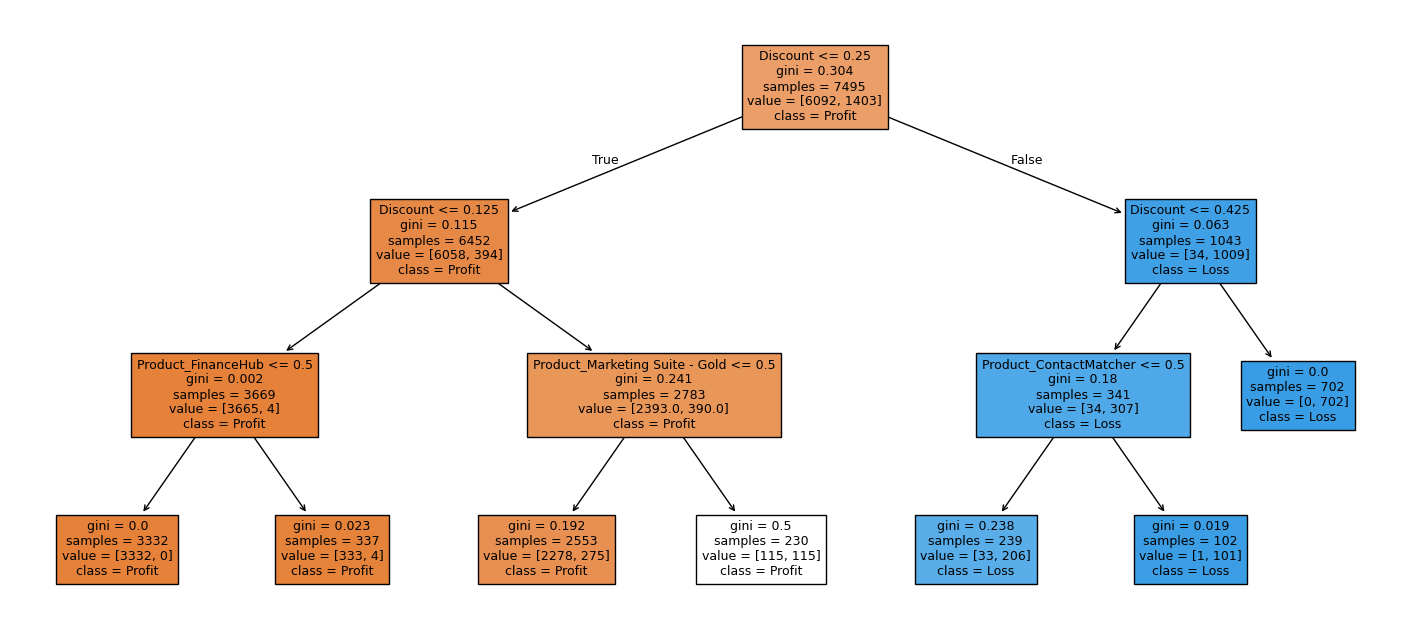

In [10]:
plt.figure(figsize=(18,8))
plot_tree(tree, feature_names=list(X.columns), class_names=['Profit','Loss'], filled=True, fontsize=9)
plt.savefig("Images/decision_tree.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
low_d = df[df['Discount'] <= 0.20]
print(low_d.groupby('Product')['Is_Loss'].agg(['sum','count','mean']).round(2).sort_values('sum', ascending=False))

                            sum  count  mean
Product                                     
Marketing Suite - Gold      161    846  0.19
Data Smasher                 91    775  0.12
FinanceHub                   87    823  0.11
Marketing Suite              40    158  0.25
Site Analytics               39    780  0.05
Support                      33   1560  0.02
ContactMatcher               31   1053  0.03
SaaS Connector Pack          29    819  0.04
Storage                      12    217  0.06
Alchemy                       0     59  0.00
Big Ol Database               0     62  0.00
ChatBot Plugin                0    796  0.00
OneView                       0    399  0.00
SaaS Connector Pack - Gold    0    254  0.00


# 04 Decision Tree
- Target: Is_Loss. Features: Discount, Quantity, Sales, Segment, Product, Region. Profit and Margin excluded (target leakage). 75/25 stratified split, depth 3, min 100 rows per leaf.
- Test accuracy 94.4% (depth 2: 94.4%, depth 4: 95.1%). The one-line rule "discount above 20% = loss" also scores 94.4%, so the tree adds nothing beyond it.
- First split is Discount <= 0.25. No discounts exist between 20% and 30%, so this means above 20%.
- - Loss class: precision 0.97, recall 0.72 (339 caught, 129 missed, 11 false alarms). Of the 523 loss-making lines at discounts of 20% or less, about 72% sit in four products: Marketing Suite - Gold (161), Data Smasher (91), FinanceHub (87) and Marketing Suite (40).
- Limits: association, not cause. Synthetic sample.